In [1]:
import sys
sys.path.append("../src")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL

from series import load_monthly_revenue

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

In [6]:
y = load_monthly_revenue()

print("Months:", len(y), "| from", y.index.min().date(), "to", y.index.max().date())
print("Missing values:", int(y.isna().sum()), "| frequency:", y.index.freqstr)
print("Total revenue:", round(y.sum(), 2))
print("Last 12 months:", round(y.tail(12).sum(), 0))
print("First value:", round(y.iloc[0], 0), "| Dec 2019:", round(y["2019-12-01"], 0))
assert len(y) == 61 and y.isna().sum() == 0

Months: 61 | from 2016-01-01 to 2021-01-01
Missing values: 0 | frequency: MS
Total revenue: 55229212.69
Last 12 months: 7738703.0
First value: 649919.0 | Dec 2019: 2477296.0


In [3]:
# If seasonal swings grow with the level of the business, a log transform is justified.
rows = []
for yr in range(2016, 2021):
    sub = y[str(yr)]
    mean_m = sub.mean()
    dec = y[f"{yr}-12-01"]
    rows.append({"year": yr, "avg_month": mean_m, "december": dec,
                 "dec_minus_avg": dec - mean_m, "dec_over_avg": dec / mean_m})
print(pd.DataFrame(rows).round(2).to_string(index=False))

 year    avg_month     december  dec_minus_avg  dec_over_avg
 2016   578,899.46   998,403.46     419,504.00          1.72
 2017   618,451.86 1,287,177.07     668,725.21          2.08
 2018 1,065,746.72 2,082,206.04   1,016,459.32          1.95
 2019 1,522,031.87 2,477,295.85     955,263.98          1.63
 2020   774,552.68   651,526.44    -123,026.24          0.84


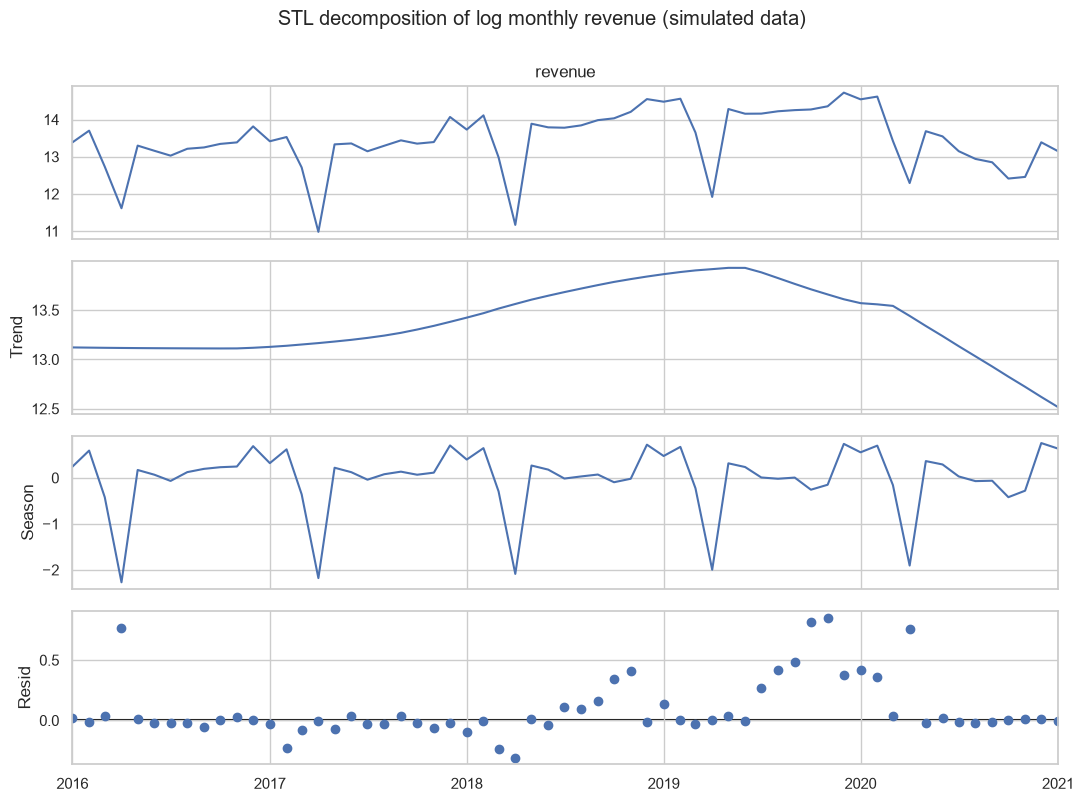

      mean    min    max
Jan 156.00 127.00 189.00
Feb 191.00 181.00 201.00
Mar  75.00  66.00  85.00
Apr  12.00  10.00  15.00
May 131.00 119.00 144.00
Jun 120.00 107.00 134.00
Jul  98.00  94.00 103.00
Aug 103.00  93.00 113.00
Sep 108.00  94.00 122.00
Oct  93.00  66.00 126.00
Nov 100.00  76.00 128.00
Dec 206.00 199.00 213.00

Residual std (log scale): 0.244 | log-series std: 0.797
Residuals beyond 2 std: ['2016-04', '2019-10', '2019-11', '2020-04']
Mean residual by year:
month
2016    0.06
2017   -0.04
2018    0.04
2019    0.28
2020    0.13
2021   -0.00


In [5]:
ly = np.log(y)
stl = STL(ly, period=12, seasonal=13, robust=True).fit()

fig = stl.plot()
fig.set_size_inches(11, 8)
fig.suptitle("STL decomposition of log monthly revenue (simulated data)", y=1.0)
plt.tight_layout()
plt.savefig("../reports/figures/stl_decomposition.png", dpi=150)
plt.show()

# Seasonal factors as percentages of an average month. The column is NOT called "month":
# the series index already has that name, which caused the ambiguity error.
sf = np.exp(stl.seasonal).rename("factor").to_frame()
sf["cal_month"] = sf.index.month
tab = sf.groupby("cal_month")["factor"].agg(["mean", "min", "max"]).mul(100).round(0)
tab.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
print(tab.to_string())

resid = stl.resid
print("\nResidual std (log scale):", round(resid.std(), 3), "| log-series std:", round(ly.std(), 3))
print("Residuals beyond 2 std:", [d.strftime("%Y-%m") for d in resid.index[abs(resid) > 2 * resid.std()]])
print("Mean residual by year:")
print(resid.groupby(resid.index.year).mean().round(2).to_string())

In [7]:
from backtest import rolling_origin, add_regime, summarise, leakage_check

def seasonal_naive(train, h):
    """Forecast each future month as the same month one year earlier."""
    n = len(train)
    return np.array([train.iloc[n - 12 + k] for k in range(h)])

bt_naive = add_regime(rolling_origin(y, seasonal_naive))

print("Origins:", bt_naive["origin"].nunique(), "| forecasts:", len(bt_naive))
print(bt_naive.groupby("regime")["origin"].nunique().to_string())
print("First origin:", bt_naive["origin"].min().date(), "| last origin:", bt_naive["origin"].max().date())
print("First target:", bt_naive["target"].min().date(), "| last target:", bt_naive["target"].max().date())

ok, n_rows = leakage_check(y, seasonal_naive)
print("Leakage check passed:", ok, "| forecasts compared:", n_rows)

first = bt_naive.iloc[0]
print(f"\nHand check: forecast for {first['target'].date()} = {first['forecast']:,.0f} "
      f"| Jan 2018 actual = {y['2018-01-01']:,.0f} | actual Jan 2019 = {first['actual']:,.0f}")

Origins: 23 | forecasts: 69
regime
pre-break             12
touches 2020 break    11
First origin: 2018-12-01 | last origin: 2020-10-01
First target: 2019-01-01 | last target: 2021-01-01
Leakage check passed: True | forecasts compared: 42

Hand check: forecast for 2019-01-01 = 917,075 | Jan 2018 actual = 917,075 | actual Jan 2019 = 1,940,900


In [8]:
res = summarise(bt_naive)
res.round(1)

n          MAE         RMSE  MAPE_%  \
pre-break          all months    36.00   388,908.80   434,126.00   29.20   
                   excl. Mar/Apr 30.00   417,666.70   456,771.50   24.90   
touches 2020 break all months    33.00   853,960.60 1,010,854.40  215.20   
                   excl. Mar/Apr 27.00 1,017,209.20 1,115,859.60  256.70   
all origins        all months    69.00   611,324.90   766,178.50  118.10   
                   excl. Mar/Apr 57.00   701,660.50   836,430.00  134.70   

                                  WAPE_%  bias_%  
pre-break          all months      25.40  -25.40  
                   excl. Mar/Apr   24.00  -24.00  
touches 2020 break all months     131.80  126.40  
                   excl. Mar/Apr  146.90  142.80  
all origins        all months      55.10   17.00  
                   excl. Mar/Apr   56.40   20.00

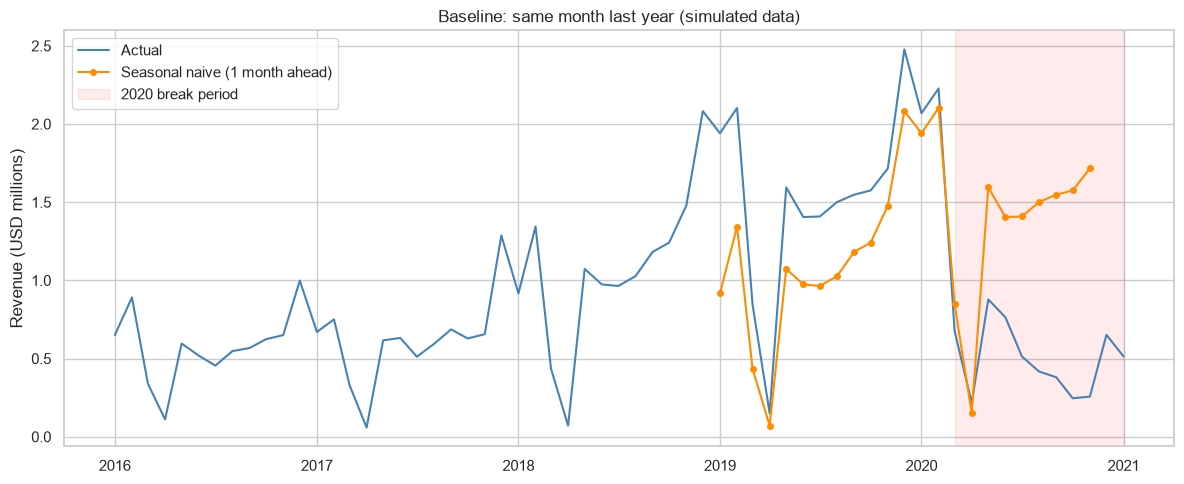

,origin,h,target,actual,forecast,abs_err
65,2020-09-01,3,2020-12-01,"651,526.00","2,477,296.00","1,825,769.00"
67,2020-10-01,2,2020-12-01,"651,526.00","2,477,296.00","1,825,769.00"
68,2020-10-01,3,2021-01-01,"513,022.00","2,068,951.00","1,555,930.00"
62,2020-08-01,3,2020-11-01,"256,701.00","1,715,660.00","1,458,959.00"
64,2020-09-01,2,2020-11-01,"256,701.00","1,715,660.00","1,458,959.00"
66,2020-10-01,1,2020-11-01,"256,701.00","1,715,660.00","1,458,959.00"
59,2020-07-01,3,2020-10-01,"245,648.00","1,575,169.00","1,329,521.00"
61,2020-08-01,2,2020-10-01,"245,648.00","1,575,169.00","1,329,521.00"


In [9]:
h1 = bt_naive[bt_naive["h"] == 1].set_index("target")
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y.index, y / 1e6, color="steelblue", label="Actual")
ax.plot(h1.index, h1["forecast"] / 1e6, color="darkorange", marker="o", markersize=4,
        label="Seasonal naive (1 month ahead)")
ax.axvspan(pd.Timestamp("2020-03-01"), y.index[-1], color="red", alpha=0.08, label="2020 break period")
ax.set_title("Baseline: same month last year (simulated data)")
ax.set_ylabel("Revenue (USD millions)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/baseline_forecast.png", dpi=150)
plt.show()

bt_naive["abs_err"] = (bt_naive["forecast"] - bt_naive["actual"]).abs()
bt_naive.nlargest(8, "abs_err")[["origin", "h", "target", "actual", "forecast", "abs_err"]] \
        .round({"actual": 0, "forecast": 0, "abs_err": 0})